# From pixels to answers

With clean, aligned images, analysis turns pixels into information: indices that measure a property, maps that sort
the ground into classes, numbers that say how good those maps are, and time series that show change. Then
**post-processing** makes the result usable: cleaning speckle, turning pixels into polygons, measuring areas, and
drawing a map someone else can read.

What you will learn: spectral indices and the science behind them; classification by thresholds, by clustering
(unsupervised) and by a random forest trained on labelled data (supervised); accuracy assessment done properly; sieving,
vectorising and measuring areas; a vegetation time series with a trend test; and the parts of a good map.

In [1]:
import importlib.util, subprocess, sys
need = {"pystac_client": "pystac-client", "planetary_computer": "planetary-computer", "rasterio": "rasterio",
        "sklearn": "scikit-learn", "geopandas": "geopandas"}
missing = [p for m, p in need.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.features import sieve, shapes
from shapely.geometry import shape
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import pystac_client, planetary_computer
plt.rcParams.update({"figure.dpi": 110})
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
BBOX = [74.60, 36.29, 74.72, 36.36]                       # Aliabad, Karimabad and the valley floor of central Hunza

# The image and its bands

We use the clearest Sentinel-2 Level-2A image of late summer 2024, when fields and orchards are green and the snow
line is high, and stack six bands at 20 m. (The preparation notebook explains each of these steps.)

In [2]:
item = sorted(catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime="2024-08-01/2024-09-30",
                             query={"eo:cloud_cover": {"lt": 5}}).items(), key=lambda i: i.properties["eo:cloud_cover"])[0]
KEYS = ["B02", "B03", "B04", "B08", "B11", "B12"]
with rasterio.open(item.assets["B11"].href) as s:
    win = from_bounds(*transform_bounds("EPSG:4326", s.crs, *BBOX), s.transform)
    shape20, crs, tf = s.read(1, window=win).shape, s.crs, s.window_transform(win)

def band(key, rule=Resampling.average):
    with rasterio.open(item.assets[key].href) as s:
        w = from_bounds(*transform_bounds("EPSG:4326", s.crs, *BBOX), s.transform)
        return s.read(1, window=w, out_shape=shape20, resampling=rule)

R = {k: (band(k).astype("float32") - 1000) / 10000 for k in KEYS}
scl = band("SCL", Resampling.nearest)
print(item.id[:38], "| cloud", item.properties["eo:cloud_cover"], "% | grid", shape20, "at 20 m, CRS", crs)

S2B_MSIL2A_20240921T054629_R048_T43SDA | cloud 0.780522 % | grid (390, 540) at 20 m, CRS EPSG:32643


# Spectral indices

An **index** combines bands so that one property stands out and others (overall brightness, illumination) cancel.
Most are **normalised differences**, $(a - b)/(a + b)$, which range from -1 to 1 and are unaffected if both bands are
scaled by the same factor, as shadow does.

| Index | Formula (Sentinel-2) | Why it works |
|---|---|---|
| NDVI, vegetation | (NIR - red) / (NIR + red) | chlorophyll absorbs red; leaf structure scatters NIR |
| NDSI, snow | (green - SWIR) / (green + SWIR) | ice is bright in green, absorbs SWIR |
| NDWI, open water | (green - NIR) / (green + NIR) | water absorbs NIR almost completely |
| NBR, burn severity | (NIR - SWIR2) / (NIR + SWIR2) | fire removes leaves (NIR falls) and dries soil (SWIR2 rises) |

**The chemistry of the red band.** Chlorophyll *a* and *b* are pigments whose molecules hold a ring of alternating
single and double bonds around a magnesium atom. Electrons in such rings are shared across the whole ring, so little
energy lifts one to a higher level: exactly the energy of blue (about 430 nm) and red (about 660 nm) photons, which
are absorbed and drive photosynthesis. Green light is absorbed less and partly reflected, so leaves look green.

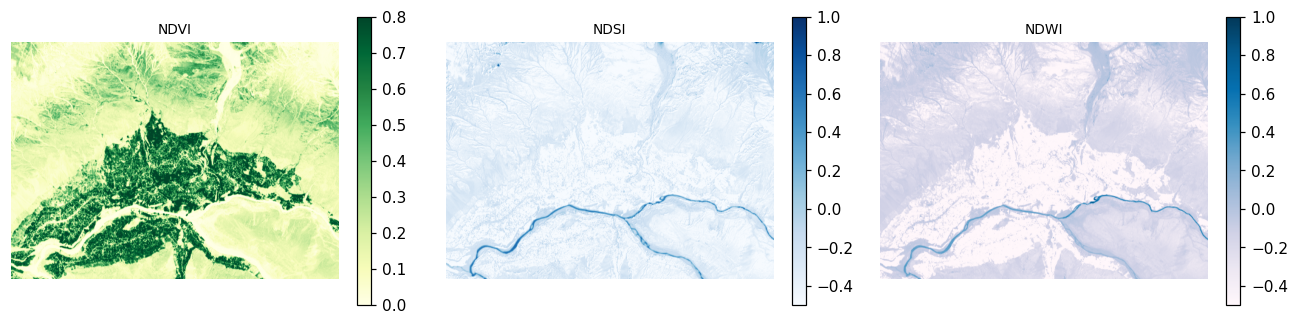

,count,mean,std,min,5%,50%,95%,max
NDVI,210600.0,0.258,0.230,-0.870,0.026,0.170,0.752,4.200
NDSI,210600.0,-0.372,0.139,-1.039,-0.557,-0.387,-0.161,0.828
NDWI,210600.0,-0.289,0.197,-2.467,-0.679,-0.229,-0.056,0.938


In [3]:
nd = lambda a, b: (R[a] - R[b]) / (R[a] + R[b])
idx = {"NDVI": nd("B08", "B04"), "NDSI": nd("B03", "B11"), "NDWI": nd("B03", "B08")}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, (name, v), cmap in zip(ax, idx.items(), ["YlGn", "Blues", "PuBu"]):
    im = a.imshow(v, cmap=cmap, vmin=-0.5 if name != "NDVI" else 0, vmax=1 if name != "NDVI" else 0.8)
    plt.colorbar(im, ax=a, fraction=0.04)
    a.set_title(name, fontsize=9)
    a.set_axis_off()
plt.tight_layout()
plt.show()
pd.DataFrame({k: pd.Series(v.ravel()).describe(percentiles=[0.05, 0.5, 0.95]) for k, v in idx.items()}).round(3).T

# Classification 1: thresholds

The simplest map applies rules to indices, in an order that settles overlaps. The thresholds are conventions, not laws
(NDSI > 0.4 is the long-standing MODIS snow rule), so a rule-based map should state its rules and be checked like any
other. Five classes are enough for this valley.

In [4]:
CLASSES = ["snow and ice", "water", "vegetation", "bare rock and soil", "built-up"]
COLOURS = ["#bbddff", "#2266cc", "#33aa33", "#bb9966", "#dd3333"]
rules = np.full(shape20, 3, "uint8")                                  # default: bare
rules[idx["NDVI"] > 0.35] = 2
rules[(idx["NDWI"] > 0.1) & (idx["NDSI"] < 0.4)] = 1
rules[(idx["NDSI"] > 0.4) & (R["B03"] > 0.2)] = 0
cmap = ListedColormap(COLOURS)
print(pd.Series(np.bincount(rules.ravel(), minlength=5) / rules.size * 100, index=CLASSES).round(1).to_string(), "\n(% of pixels)")

snow and ice           0.1
water                  0.5
vegetation            26.0
bare rock and soil    73.4
built-up               0.0 
(% of pixels)


# Classification 2: unsupervised clustering

**K-means** sorts pixels into *k* groups so that each pixel is closer (in band space) to its group's centre than to any
other. It needs no labels, but it does not know what the groups are: a person must name them afterwards, and one
land cover may split across clusters or two may merge. It is useful for exploring an image, not for a final map.

In [5]:
X = np.stack([R[k].ravel() for k in KEYS], axis=1)
km = KMeans(n_clusters=6, n_init=4, random_state=0).fit(X[::7])
clusters = km.predict(X).reshape(shape20)
centres = pd.DataFrame(km.cluster_centers_, columns=KEYS).round(3)
centres["NDVI"] = ((centres.B08 - centres.B04) / (centres.B08 + centres.B04)).round(2)
centres["NDSI"] = ((centres.B03 - centres.B11) / (centres.B03 + centres.B11)).round(2)
centres["share_%"] = (np.bincount(clusters.ravel(), minlength=6) / clusters.size * 100).round(1)
centres

,B02,B03,B04,B08,B11,B12,NDVI,NDSI,share_%
0,0.086,0.108,0.119,0.188,0.245,0.223,0.22,-0.39,31.4
1,0.178,0.215,0.238,0.286,0.366,0.357,0.09,-0.26,9.6
2,0.042,0.065,0.055,0.266,0.178,0.121,0.66,-0.47,19.9
3,0.281,0.337,0.371,0.466,0.555,0.532,0.11,-0.24,1.0
4,0.119,0.148,0.168,0.217,0.303,0.291,0.13,-0.34,30.8
5,0.072,0.083,0.084,0.108,0.150,0.137,0.13,-0.29,7.3


# Classification 3: supervised, with reference labels

A **supervised** classifier learns from pixels whose class is known. Collecting such labels in the field is the gold
standard; here we borrow them from **ESA WorldCover 2021**, a global 10 m land cover map, keeping in mind that it has
its own errors (about 75% overall accuracy globally) and a different date, so this shows the method, not a validated
map. Its classes are merged into our five.

The classifier is a **random forest**: many decision trees, each trained on a random sample of pixels and bands, that
vote. It handles bands on different scales and non-linear boundaries with little tuning.

**Testing honestly.** Neighbouring pixels are almost identical, so if training and test pixels are drawn at random from
the same image, the test pixels have near-copies in the training set and the accuracy is flattering. The remedy is a
**spatial split**: divide the image into blocks and keep whole blocks for testing.

In [6]:
wc = next(catalog.search(collections=["esa-worldcover"], bbox=BBOX).items())
with rasterio.open(wc.assets["map"].href) as s:
    ref = np.zeros(shape20, "uint8")
    reproject(rasterio.band(s, 1), ref, dst_transform=tf, dst_crs=crs, resampling=Resampling.mode)
WC = {70: 0, 80: 1, 10: 2, 20: 2, 30: 2, 40: 2, 90: 2, 95: 2, 100: 2, 60: 3, 50: 4}   # WorldCover code -> our class
labels = np.vectorize(lambda v: WC.get(int(v), 255))(ref).astype("uint8")
print("WorldCover classes present:", sorted(np.unique(ref).tolist()), "| labelled share", round(np.mean(labels < 255), 3))

block = 40                                                              # 40 x 40 pixels = 800 m blocks
bid = (np.arange(shape20[0])[:, None] // block) * 1000 + (np.arange(shape20[1])[None, :] // block)
rng = np.random.default_rng(0)
test_blocks = rng.choice(np.unique(bid), size=int(0.3 * np.unique(bid).size), replace=False)
is_test = np.isin(bid, test_blocks)
y = labels.ravel()
ok = (y < 255) & np.isfinite(X).all(1)
train = ok & ~is_test.ravel()
test = ok & is_test.ravel()
sample = np.flatnonzero(train)[rng.permutation(train.sum())[:20000]]
rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=3, random_state=0, n_jobs=-1).fit(X[sample], y[sample])
pred = rf.predict(X).reshape(shape20)
print("training pixels", len(sample), "| test pixels", int(test.sum()), "in", len(test_blocks), "held-out blocks")

WorldCover classes present: [10, 30, 40, 50, 60, 70, 80, 100] | labelled share 1.0


training pixels 20000 | test pixels 60800 in 42 held-out blocks


# Accuracy assessment

The **confusion matrix** counts, for test pixels, the reference class (rows) against the predicted class (columns).
From it:

* **overall accuracy**: the share on the diagonal;
* **producer's accuracy** (recall) for a class: of the pixels that truly are that class, the share mapped correctly
  (the map-maker's view: what did I miss?);
* **user's accuracy** (precision): of the pixels mapped as that class, the share that truly are (the map-user's view:
  if the map says forest, how often is it?);
* **Cohen's kappa**: agreement beyond what chance would give, $\kappa = (p_o - p_e)/(1 - p_e)$, though many now prefer
  to report the matrix and per-class accuracies instead.

Rare classes matter: 95% overall accuracy can hide a class mapped entirely wrong. We score the maps on the same
held-out blocks, and the random forest also on randomly chosen pixels.

In [7]:
def scores(p, mask):
    cm = confusion_matrix(y[mask], p.ravel()[mask], labels=range(5))
    oa = np.trace(cm) / cm.sum()
    return cm, oa, cohen_kappa_score(y[mask], p.ravel()[mask])

rows = []
for name, m in [("thresholds", rules), ("random forest", pred)]:
    cm, oa, k = scores(m, test)
    rows.append(dict(map=name, test="spatial blocks", overall_accuracy=oa, kappa=k))
rand = ok & (rng.random(ok.size) < 0.3) & ~np.isin(np.arange(ok.size), sample)
cm_r, oa_r, k_r = scores(pred, rand)
rows.append(dict(map="random forest", test="random pixels (flattering)", overall_accuracy=oa_r, kappa=k_r))
print(pd.DataFrame(rows).round(3).to_string(index=False))
cm, oa, k = scores(pred, test)
cmd = pd.DataFrame(cm, index=[f"ref: {c}" for c in CLASSES], columns=[f"map: {c}" for c in CLASSES])
cmd["producer's"] = (np.diag(cm) / cm.sum(1).clip(1)).round(2)
cmd.loc["user's"] = list((np.diag(cm) / cm.sum(0).clip(1)).round(2)) + [round(oa, 2)]
cmd

          map                       test  overall_accuracy  kappa
   thresholds             spatial blocks             0.739  0.437
random forest             spatial blocks             0.856  0.714
random forest random pixels (flattering)             0.844  0.705


,map: snow and ice,map: water,map: vegetation,map: bare rock and soil,map: built-up,producer's
ref: snow and ice,84.0,7.00,1.00,347.00,0.0,0.19
ref: water,9.0,511.00,10.00,189.00,0.0,0.71
ref: vegetation,0.0,0.00,19417.00,4100.00,31.0,0.82
ref: bare rock and soil,115.0,94.00,2763.00,31998.00,27.0,0.91
ref: built-up,0.0,0.00,347.00,691.00,59.0,0.05
user's,0.4,0.83,0.86,0.86,0.5,0.86


**Reading the results.** The random forest beats the thresholds by a wide margin, partly because the rules have no
built-up class at all: every village pixel is wrong by design. Here the random-pixel score is no higher than the
spatial one, and the same held when we trained on every pixel of the training blocks (0.852 with a random split
against 0.859 with spatial blocks). In this image the ceiling is set by disagreement with the reference map itself,
which has its own errors and a different year, not by leakage. Spatial testing matters most when labels come from a
few dense patches or the property varies smoothly in space; Ploton et al. (2020, *Nature Communications*,
doi:10.1038/s41467-020-18321-y) showed a published biomass map whose random-split accuracy disappeared under spatial
testing. So use spatial splits by default: when leakage is absent they cost nothing, and when present they reveal it.

# Post-processing: sieve, polygons and areas

Pixel classifiers leave **speckle**: single pixels of one class inside another. A **sieve** replaces patches smaller than
a minimum size with their surroundings; choose the size from the smallest feature you care about (here 6 pixels, about
0.24 ha). **Vectorising** turns patches into polygons that a GIS can edit and attach attributes to. **Areas** must be
measured in an equal-area or local projected CRS (UTM is fine at this scale), never in degrees.

In [8]:
clean = sieve(pred.astype("uint8"), size=6)
changed = np.mean(clean != pred)
polys = [dict(cls=CLASSES[int(v)], geometry=shape(g)) for g, v in shapes(clean, transform=tf)]
gdf = gpd.GeoDataFrame(polys, crs=crs)
gdf["area_km2"] = gdf.area / 1e6
summary = gdf.groupby("cls").agg(polygons=("area_km2", "size"), area_km2=("area_km2", "sum")).round(2)
print(f"sieve changed {100 * changed:.1f}% of pixels; {len(gdf):,} polygons")
summary

sieve changed 3.8% of pixels; 701 polygons


,polygons,area_km2
cls,,
bare rock and soil,366,46.14
snow and ice,15,0.29
vegetation,315,36.69
water,5,1.12


# A time series and a trend test

Change is found by repeating a measurement over time. We take every Sentinel-2 image of 2018-2025 for a patch of
irrigated fields and orchards on the valley floor, mask cloud with the scene classification, and keep the median NDVI
of each image. The seasonal cycle (green-up in spring, harvest in autumn, bare in winter) dominates, so to ask whether
summers are getting greener or browner we take the **July-August median** of each year.

**Testing for a trend.** The **Mann-Kendall test** asks whether later values tend to be larger (or smaller) than earlier
ones, without assuming a straight line or normal errors. For $n$ values it counts every pair: $S = \sum_{i<j}
\operatorname{sign}(x_j - x_i)$. With no trend, $S$ has mean 0 and variance $n(n-1)(2n+5)/18$, so
$Z = (S - \operatorname{sign}S)/\sqrt{\operatorname{Var}S}$ is close to a standard normal, giving a *p*-value. The
**Sen slope**, the median of the slopes between all pairs, measures the size. A *p*-value above 0.05 does not mean "no
change": it means the record is too short or too variable to tell. With 8 summers, only large trends can be detected.

258 images found, 240 clear enough; summers: 8
Mann-Kendall S = 4, Z = 0.37, p = 0.711; Sen slope +0.014 NDVI per decade
check against scipy's Kendall tau p: 0.72


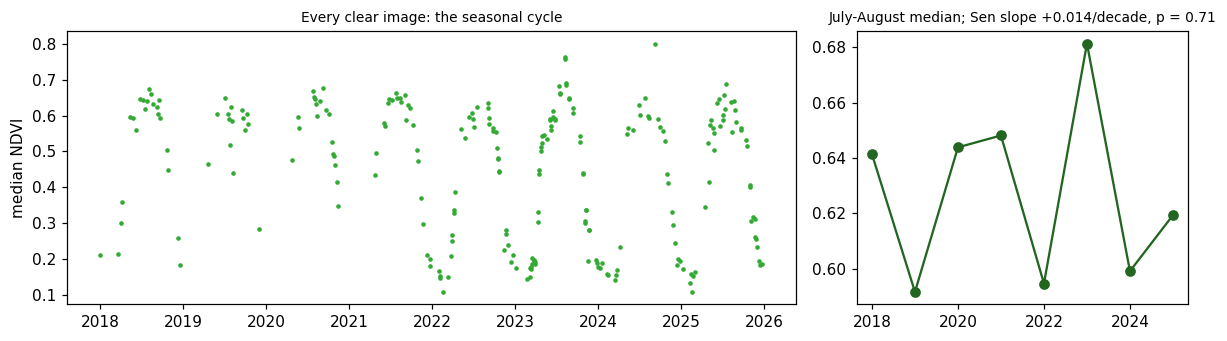

In [9]:
FIELDS = [74.655, 36.310, 74.675, 36.320]
ts_items = list(catalog.search(collections=["sentinel-2-l2a"], bbox=FIELDS, datetime="2018-01-01/2025-12-31",
                               query={"eo:cloud_cover": {"lt": 40}, "s2:mgrs_tile": {"eq": item.properties["s2:mgrs_tile"]}}).items())
recs = []
for it in ts_items:
    def rd(key, rule=Resampling.average):
        with rasterio.open(it.assets[key].href) as s:
            w = from_bounds(*transform_bounds("EPSG:4326", s.crs, *FIELDS), s.transform)
            return s.read(1, window=w, out_shape=(55, 90), resampling=rule).astype("float32")
    off = -1000 if float(it.properties["s2:processing_baseline"]) >= 4 else 0
    sc = rd("SCL", Resampling.nearest)
    good = np.isin(sc, [4, 5])                                       # vegetation or bare ground: clear land
    if good.mean() < 0.6:
        continue
    nir, red = (rd("B08") + off) / 1e4, (rd("B04") + off) / 1e4
    recs.append(dict(date=pd.Timestamp(it.properties["datetime"][:10]), ndvi=float(np.median(((nir - red) / (nir + red))[good]))))
ts = pd.DataFrame(recs).sort_values("date").reset_index(drop=True)
summer = ts[ts.date.dt.month.isin([7, 8])].groupby(ts.date.dt.year).ndvi.median()
n = len(summer)
s_stat = sum(np.sign(summer.values[j] - summer.values[i]) for i in range(n) for j in range(i + 1, n))
z = (s_stat - np.sign(s_stat)) / np.sqrt(n * (n - 1) * (2 * n + 5) / 18)
p = 2 * stats.norm.sf(abs(z))
sen = np.median([(summer.values[j] - summer.values[i]) / (summer.index[j] - summer.index[i]) for i in range(n) for j in range(i + 1, n)])
print(f"{len(ts_items)} images found, {len(ts)} clear enough; summers: {n}")
print(f"Mann-Kendall S = {s_stat:.0f}, Z = {z:.2f}, p = {p:.3f}; Sen slope {sen * 10:+.3f} NDVI per decade")
print("check against scipy's Kendall tau p:", round(stats.kendalltau(summer.index, summer.values).pvalue, 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(ts.date, ts.ndvi, ".", ms=4, color="#33aa33")
ax[0].set_ylabel("median NDVI")
ax[0].set_title("Every clear image: the seasonal cycle", fontsize=9)
ax[1].plot(summer.index, summer.values, "o-", color="#226622")
ax[1].set_title(f"July-August median; Sen slope {sen * 10:+.3f}/decade, p = {p:.2f}", fontsize=9)
plt.tight_layout()
plt.show()

# Making a map someone else can read

A map for others needs: a **title** saying what and when; a **legend** naming every colour; a **scale bar**; a **north
arrow** if north is not up; the **source and date** of the data; the **projection**; and colours that people with
colour-vision deficiency can tell apart (avoid red against green as the only difference; check with a simulator).

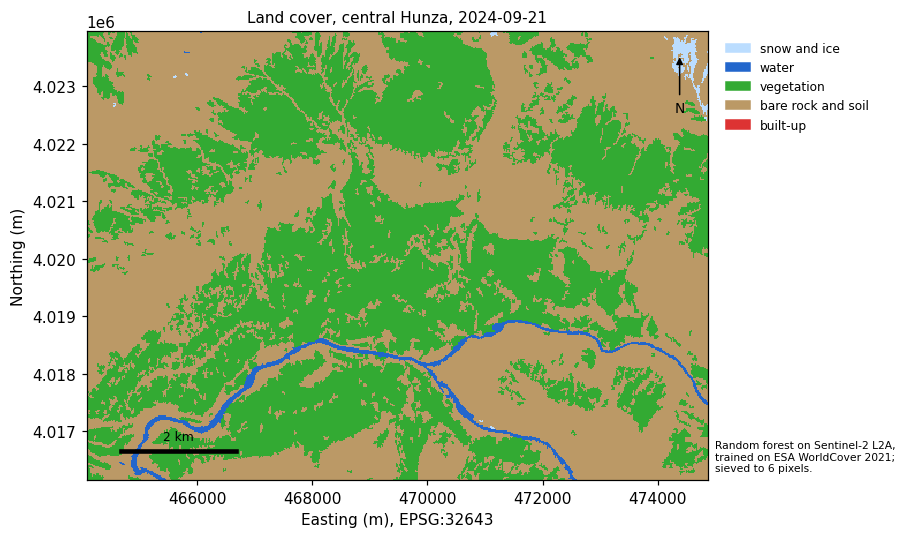

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ext = rasterio.transform.array_bounds(*shape20, tf)
ax.imshow(clean, cmap=cmap, vmin=-0.5, vmax=4.5, extent=[ext[0], ext[2], ext[1], ext[3]], interpolation="nearest")
x0, y0 = ext[0] + 600, ext[1] + 500
ax.plot([x0, x0 + 2000], [y0, y0], color="black", lw=3)
ax.text(x0 + 1000, y0 + 200, "2 km", ha="center", fontsize=8)
ax.annotate("N", xy=(ext[2] - 500, ext[3] - 400), xytext=(ext[2] - 500, ext[3] - 1400), ha="center",
            arrowprops=dict(arrowstyle="-|>", color="black"), fontsize=9)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOURS], CLASSES, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
ax.set_title(f"Land cover, central Hunza, {item.properties['datetime'][:10]}", fontsize=10)
ax.set_xlabel(f"Easting (m), {crs}")
ax.set_ylabel("Northing (m)")
ax.text(1.01, 0.02, "Random forest on Sentinel-2 L2A,\ntrained on ESA WorldCover 2021;\nsieved to 6 pixels.", transform=ax.transAxes, fontsize=7)
plt.tight_layout()
plt.show()

# What to remember

* Indices work because of physics, chemistry and biology; know which, and their limits.
* Rules, clusters and trained classifiers each have their place; all must be checked against reference data.
* Test on spatially separate data, and report the confusion matrix and per-class accuracies, not only one number.
* Clean speckle, measure areas in a projected CRS, and keep a map's title, legend, scale, source and projection.
* A trend test says whether a record can show change, not whether change happened: report the slope with the test.

**Exercises.** (1) Change the block size of the spatial split to 10 and 100 pixels and watch the accuracy. (2) Add
NDVI and NDSI as features to the random forest: does accuracy rise? (3) Repeat the time series for a patch of bare
hillside and compare its year-to-year variability with the fields.